# Lateral Color

Lateral color (transverse chromatic aberration) is the change of image height with wavelength. For each field point, the real chief ray is traced at every wavelength, and its height on the image surface is compared with the chief-ray height at the primary wavelength.

In [1]:
from optiland.analysis import LateralColor
from optiland.samples.objectives import DoubleGauss

In [2]:
lens = DoubleGauss()

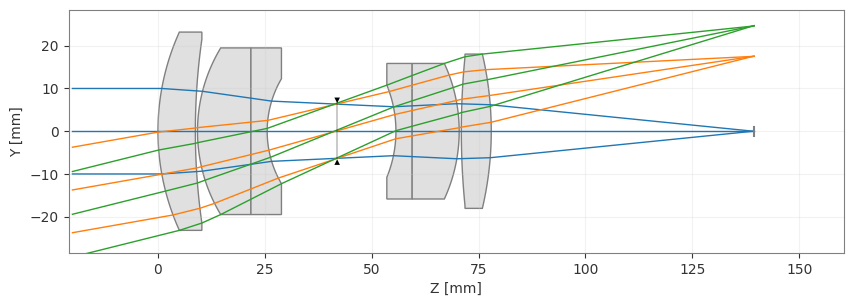

In [3]:
fig, ax = lens.draw()

By default the analysis uses the optic's defined wavelengths, here the F, d and C lines.

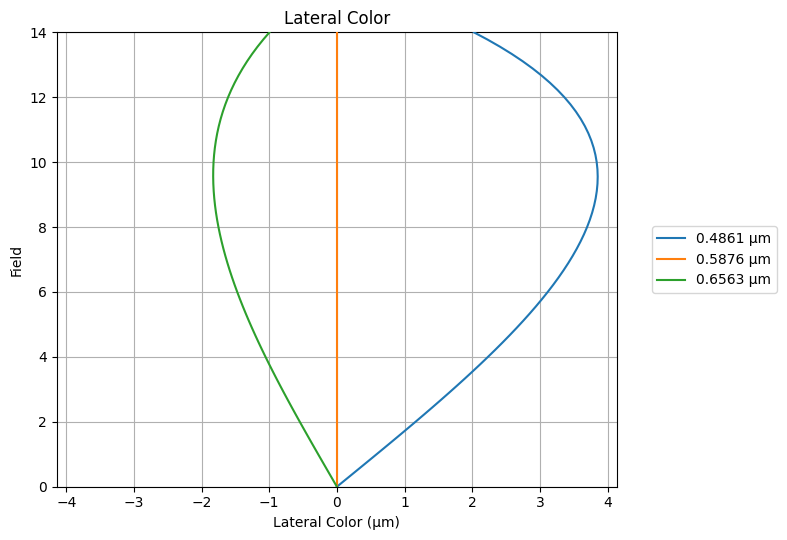

In [4]:
lc = LateralColor(lens)
fig, ax = lc.view()

How to read the plot:

- The x-axis is `y(λ) − y(primary)` in µm, the chief-ray height at each wavelength minus the height at the primary wavelength. The image height of this lens is positive, so a positive value means that wavelength lands farther from the axis. For an inverted image the meaning flips.
- The y-axis is the field. Every curve starts at zero on axis, and the primary wavelength is the flat zero line.
- The horizontal distance between two curves is the lateral color between those wavelengths at that field. It is usually compared with the pixel size or the Airy radius.

Near the axis, lateral color grows linearly with field, and its slope matches the first-order lateral color coefficient `TchC`, summed over surfaces. `TchC` uses the shortest minus the longest wavelength, so the comparison below uses the same order.

In [5]:
import optiland.backend as be

values = lens.wavelengths.get_wavelengths()
short, long = min(values), max(values)
lc_fc = LateralColor(lens, wavelengths=[short, long])
y_short, y_long = lc_fc.data["lateral_color"]
hy = lc_fc.data["Hy"]

slope = (y_short[1] - y_long[1]) / hy[1]
tchc = be.sum(lens.aberrations.TchC())
print(f"Real-ray slope near axis: {float(slope) * 1e3:.2f} µm per unit field")
print(f"Sum of TchC:              {float(tchc) * 1e3:.2f} µm")
print(f"Real ray at full field:   {float(y_short[-1] - y_long[-1]) * 1e3:.2f} µm")

Real-ray slope near axis: 12.12 µm per unit field
Sum of TchC:              12.27 µm
Real ray at full field:   3.02 µm


The real-ray value at full field differs from the first-order prediction because of higher-order lateral color, which this analysis includes.